In [1]:
import numpy as np
import matplotlib.pyplot as plt


def sigmoid(x,w,b):
    z = x @ w + b
    return 1/( 1+np.exp(-z))

def log_likelihood(x,y,w,b):

    p = sigmoid(x,w,b)
    #p는 모든 x,y에 대한 확률이 나온다
    #for log clipping
    eps = 1e-12
    p = np.clip(p,eps,1-eps)

    #모든 p값에 대해서 log_likelyhood를 구한다

    return np.sum(y*np.log(p) + (1-y)*np.log(1-p))

def crossEntropy(x,y,w,b):

    N = x.shape[0]

    return -log_likelihood(x,y,w,b)/N

def grad_cross_entropy(x, y, w, b):
    """배치 평균 cross entropy의 gradient (loss를 줄이는 방향의 반대, 즉 descent용)"""
    p = sigmoid(x, w, b)
    dw = x.T @ (p - y) / x.shape[0]
    db = np.mean(p - y)
    return dw, db


def logisticRegression(x,y,learning_rate,epoches,batch_size,seed = None):
    

    N,D = x.shape
    
    rng = np.random.default_rng(seed)
    w = rng.standard_normal(D)
    b = rng.standard_normal()

    history = {'w': [w.copy()], 'b': [b], 'loss': [crossEntropy(x, y, w, b)]}


    for epoch in range(epoches):

        idx = rng.permutation(N)

        for start in range(0,N, batch_size):
            batch = idx[start : start + batch_size]

            dw, db = grad_cross_entropy(x[batch], y[batch], w, b)

            w = w - learning_rate * dw
            b = b - learning_rate * db


        loss = crossEntropy(x,y,w,b)
        history['w'].append(w.copy())
        history['b'].append(b)
        history['loss'].append(loss)

        print(f"Epoch {epoch+1}/{epoches}, Loss: {loss:.4f}, "
        f"w: {np.round(w, 3)}, b: {b:.4f}")

    plt.plot(history['loss'])
    plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.show()
    return history


In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

x, y = load_breast_cancer(return_X_y=True)
x = StandardScaler().fit_transform(x)   # 스케일링 필수
y = y.astype(float)

sklearn
[[ 18.58066496  -0.5269548   12.58652781  -4.14505929  -6.66234512
   23.64969068 -21.57754108  -8.51549778   3.92376703  -1.81857739
  -11.13519518   4.83710181  12.18499256 -20.91486342  -0.67271169
   -9.92999279  15.19356121 -17.91969458   3.99191822  20.22198519
  -11.69447976  -8.92845014 -12.05614392 -23.33265578   2.97352772
    3.03714362  -6.30900222   2.44872394  -7.29594148 -13.18450747]] [-5.777415]
my logsitc
Epoch 1/2000, Loss: 0.6215, w: [-0.093 -0.317  0.426 -0.096 -0.517  0.301  1.185  0.792 -0.658 -1.123
 -0.684  0.078 -2.378 -0.31  -1.088 -0.68  -0.504 -0.287  0.528  1.15
 -0.35   1.144 -0.881  0.153  0.844 -0.016 -0.88  -1.102 -0.537  0.198], b: -0.8581
Epoch 2/2000, Loss: 0.3999, w: [-0.211 -0.432  0.312 -0.205 -0.487  0.296  1.139  0.719 -0.605 -1.017
 -0.705  0.1   -2.391 -0.356 -0.985 -0.609 -0.441 -0.225  0.605  1.241
 -0.472  0.998 -0.996  0.044  0.81  -0.058 -0.936 -1.188 -0.58   0.198], b: -0.7544
Epoch 3/2000, Loss: 0.2975, w: [-0.284 -0.516  0.241

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Epoch 137/2000, Loss: 0.0594, w: [-0.683 -1.239 -0.151 -0.749 -0.634  0.562  0.343 -0.13  -0.062 -0.526
 -0.828  0.046 -2.125 -0.711 -0.791  0.334 -0.08   0.243  0.652  1.647
 -1.176 -0.574 -1.547 -0.693 -0.143  0.032 -1.526 -1.89  -1.149 -0.111], b: 0.3064
Epoch 138/2000, Loss: 0.0593, w: [-0.683 -1.239 -0.152 -0.75  -0.634  0.564  0.341 -0.132 -0.061 -0.524
 -0.829  0.047 -2.124 -0.712 -0.791  0.337 -0.08   0.242  0.651  1.647
 -1.177 -0.577 -1.548 -0.695 -0.144  0.034 -1.528 -1.892 -1.15  -0.112], b: 0.3073
Epoch 139/2000, Loss: 0.0592, w: [-0.684 -1.239 -0.152 -0.751 -0.634  0.566  0.338 -0.135 -0.059 -0.522
 -0.83   0.047 -2.123 -0.713 -0.791  0.339 -0.08   0.242  0.65   1.648
 -1.179 -0.58  -1.548 -0.696 -0.146  0.035 -1.53  -1.893 -1.151 -0.112], b: 0.3079
Epoch 140/2000, Loss: 0.0592, w: [-0.684 -1.238 -0.152 -0.751 -0.635  0.568  0.335 -0.138 -0.058 -0.521
 -0.831  0.048 -2.122 -0.714 -0.792  0.342 -0.08   0.242  0.65   1.649
 -1.18  -0.583 -1.549 -0.698 -0.148  0.036 -1.532 -

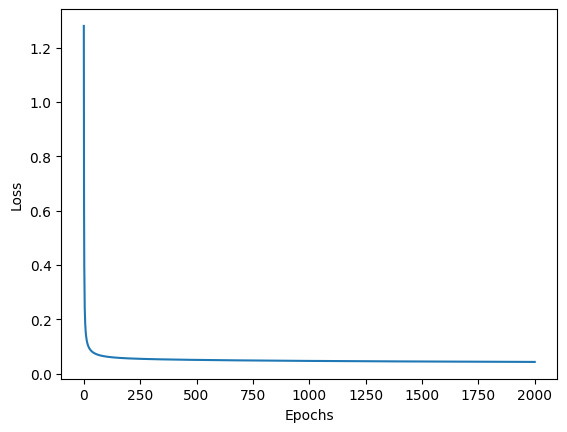

[-0.17046655 -0.17007393  0.36889757 -0.43548624 -0.63341334  2.07102741
 -0.93008361 -1.66093415  0.47299096 -0.07004919 -2.16415903  0.55007583
 -1.5776073  -1.86798555 -0.92994315  0.61856884  0.48924652 -0.21507887
  0.36909484  1.89332947 -1.98972693 -2.37089493 -1.72193292 -1.58624851
 -0.2887585   0.6479285  -2.01273073 -2.26638569 -1.46295556 -1.23456105] -0.3520763563853514


In [5]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(penalty=None).fit(x, y)


print("sklearn")
print(clf.coef_, clf.intercept_)

print("my logsitc")

hist = logisticRegression(x, y, 0.1, 2000, 64, seed=0)
print(hist['w'][-1], hist['b'][-1])

In [6]:
pred = (sigmoid(x, hist['w'][-1], hist['b'][-1]) > 0.5).astype(float)
print("accuracy:", (pred == y).mean())

accuracy: 0.9894551845342706


Epoch 1/500, Loss: 0.4430, w: [-0.187 -0.369  0.334 -0.184 -0.493  0.289  1.143  0.73  -0.615 -1.034
 -0.717  0.105 -2.406 -0.352 -0.972 -0.636 -0.458 -0.231  0.584  1.213
 -0.448  1.065 -0.974  0.064  0.842 -0.053 -0.931 -1.167 -0.561  0.206], b: -0.7758
Epoch 2/500, Loss: 0.2651, w: [-0.304 -0.505  0.22  -0.292 -0.476  0.27   1.091  0.65  -0.551 -0.942
 -0.74   0.121 -2.419 -0.402 -0.855 -0.566 -0.369 -0.13   0.668  1.302
 -0.576  0.886 -1.096 -0.05   0.778 -0.123 -1.002 -1.263 -0.619  0.17 ], b: -0.6441
Epoch 3/500, Loss: 0.1903, w: [-0.378 -0.609  0.147 -0.364 -0.44   0.261  1.056  0.608 -0.486 -0.89
 -0.75   0.131 -2.421 -0.435 -0.769 -0.518 -0.315 -0.048  0.727  1.348
 -0.661  0.744 -1.176 -0.129  0.738 -0.166 -1.049 -1.323 -0.653  0.136], b: -0.5375
Epoch 4/500, Loss: 0.1591, w: [-4.200e-01 -6.730e-01  1.060e-01 -4.060e-01 -4.420e-01  2.580e-01
  1.031e+00  5.740e-01 -4.560e-01 -8.580e-01 -7.650e-01  1.200e-01
 -2.426e+00 -4.600e-01 -7.340e-01 -4.790e-01 -2.770e-01  1.000e-03
  

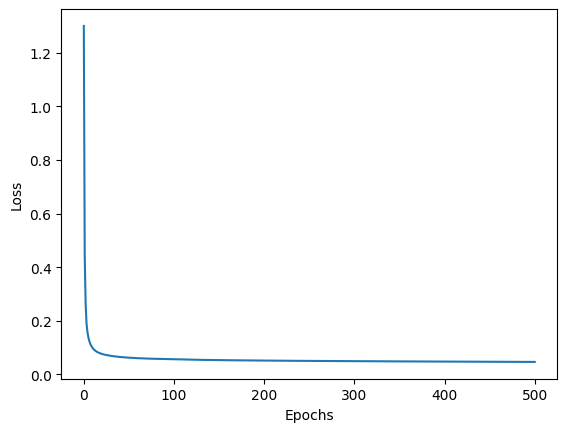

test acc: 0.9473684210526315


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.2, random_state=0)
scaler = StandardScaler().fit(x_tr)          # 학습 데이터로만 fit
x_tr, x_te = scaler.transform(x_tr), scaler.transform(x_te)

hist = logisticRegression(x_tr, y_tr, 0.1, 500, 32, seed=0)
w, b = hist['w'][-1], hist['b'][-1]
print("test acc:", ((sigmoid(x_te, w, b) > 0.5) == y_te).mean())